# Visualización 3D de casos ImageCAS

Notebook independiente para la exploración visual de los volúmenes CTA y de sus segmentaciones (ground truth o predicciones de cualquiera de los modelos entrenados), separado de los notebooks de entrenamiento y evaluación.

Se utilizan dos formas de visualización:
1. **Slider por cortes**, compatible con Colab.
2. **Visor 3D interactivo** con `itkwidgets` (rotación y zoom con el ratón).

Nota: `sitk.Show()`, el visor nativo de SimpleITK, no funciona en Colab, ya que lanza un programa externo (ImageJ/Fiji) que requiere pantalla.


In [1]:
from google.colab import drive
drive.mount("/content/drive")


Mounted at /content/drive


In [2]:
import os
from pathlib import Path

BASE = Path("/content/drive/MyDrive/TFM_nnUNet")
NNUNET_RAW = BASE / "nnUNet_raw"
NNUNET_RESULTS = BASE / "nnUNet_results"

os.environ["nnUNet_raw"] = str(NNUNET_RAW)
os.environ["nnUNet_results"] = str(NNUNET_RESULTS)


In [3]:
!pip install -q SimpleITK


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.8/52.8 MB 20.4 MB/s eta 0:00:00


In [4]:
import SimpleITK as sitk
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, IntSlider


## 1. Selección del caso y de la máscara

Se puede visualizar el ground truth (`labelsTr`) o la predicción de cualquiera de los modelos entrenados (carpeta `validation` de cada trainer).


In [5]:
DATASET_NAME  = "Dataset501_ImageCAS"
PLANS_NAME    = "nnUNetPlans"
CONFIGURATION = "3d_fullres"
FOLD          = 0
CASE_ID       = "ImageCAS_0011"  # cambia por cualquier caso que tengas

IMAGE_PATH = NNUNET_RAW / DATASET_NAME / "imagesTr" / f"{CASE_ID}_0000.nii.gz"

# Ground truth
LABEL_PATH = NNUNET_RAW / DATASET_NAME / "labelsTr" / f"{CASE_ID}.nii.gz"

# Alternativa: predicción de un modelo entrenado (se sustituye la línea anterior
# por la siguiente, con el nombre del trainer correspondiente)
# TRAINER = "nnUNetTrainerSoftClDice100epochs"
# LABEL_PATH = (NNUNET_RESULTS / DATASET_NAME
#               / f"{TRAINER}__{PLANS_NAME}__{CONFIGURATION}"
#               / f"fold_{FOLD}" / "validation" / f"{CASE_ID}.nii.gz")

print("Imagen: ", IMAGE_PATH, "-> existe:", IMAGE_PATH.exists())
print("Mascara:", LABEL_PATH, "-> existe:", LABEL_PATH.exists())


Imagen:  /content/drive/MyDrive/TFM_nnUNet/nnUNet_raw/Dataset501_ImageCAS/imagesTr/ImageCAS_0011_0000.nii.gz -> existe: True
Mascara: /content/drive/MyDrive/TFM_nnUNet/nnUNet_raw/Dataset501_ImageCAS/labelsTr/ImageCAS_0011.nii.gz -> existe: True


In [6]:
ct = sitk.GetArrayFromImage(sitk.ReadImage(str(IMAGE_PATH))).astype(np.float32)
mask = sitk.GetArrayFromImage(sitk.ReadImage(str(LABEL_PATH))).astype(bool)

print("Forma del volumen (z, y, x):", ct.shape)
print("Voxeles de vaso en la mascara:", mask.sum())


Forma del volumen (z, y, x): (275, 512, 512)
Voxeles de vaso en la mascara: 70200


## 2. Opción A — Slider interactivo por cortes

Recorrido de todos los cortes axiales del volumen mediante un control deslizante, con la segmentación superpuesta en rojo. Esta opción es compatible con Colab.


In [7]:
from ipywidgets import IntSlider, Checkbox, VBox, Output
from ipywidgets import interactive_output
from IPython.display import display, clear_output

WINDOW_CENTER, WINDOW_WIDTH = 300, 700  # ajusta si el vaso se ve muy oscuro/claro
vmin, vmax = WINDOW_CENTER - WINDOW_WIDTH/2, WINDOW_CENTER + WINDOW_WIDTH/2

z_slider = IntSlider(min=0, max=ct.shape[0]-1, step=1, value=ct.shape[0]//2, description="z")
overlay_check = Checkbox(value=True, description="overlay")
out = Output()

def show_slice(z, overlay):
    with out:
        clear_output(wait=True)  # IMPORTANTE: sin esto, Colab no refresca la imagen
        plt.figure(figsize=(6,6))
        plt.imshow(ct[z], cmap="gray", vmin=vmin, vmax=vmax)
        if overlay:
            m = np.ma.masked_where(~mask[z], mask[z])
            plt.imshow(m, cmap="autumn", alpha=0.6)
        plt.axis("off")
        plt.title(f"Corte axial {z}/{ct.shape[0]}  ({CASE_ID})")
        plt.show()

ui = interactive_output(show_slice, {"z": z_slider, "overlay": overlay_check})
display(VBox([z_slider, overlay_check, out]))


## 3. Opción B (descartada) — Visor 3D interactivo con itkwidgets

Se evaluó `itkwidgets.view()` para obtener un render 3D navegable. Sin embargo, la llamada falla de forma reproducible en Colab con un `TraitError` al recibir la máscara de segmentación (`label_image_weights shape expected to have 1 components, but got () components`), un problema de compatibilidad de la librería con arrays de NumPy en crudo. Se descarta esta opción: el slider de la sección 2 y la MIP de la sección 4 cubren la inspección visual necesaria.


## 4. Proyección de máxima intensidad (MIP)

Alternativa ligera a un visor 3D: proyecta todo el árbol vascular en una única imagen 2D de tipo angiografía, sin necesidad de librerías adicionales.


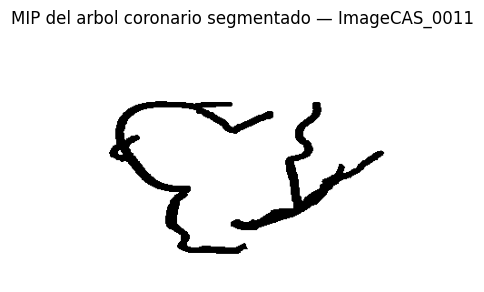

In [8]:
mip = mask.max(axis=1)  # proyeccion a lo largo del eje Y (coronal)

plt.figure(figsize=(6,8))
plt.imshow(mip, cmap="gray_r")
plt.title(f"MIP del arbol coronario segmentado — {CASE_ID}")
plt.axis("off")
plt.show()
